# H2 supporting study: the pooler


MiniLM-L6, MiniLM-L12 and mxbai-v1 respond least to the invariance term out of
distribution, and they are the three models whose LoRA fine-tuning left the
pooler's dense layer frozen, which the three XLM-RoBERTa models train as part of
their classifier. Each of the three is trained again with the pooler unfrozen,
at the base model's chosen weight and over the same five seeds.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from fsr.h2_pooler import (
    CHOSEN,
    DENSE,
    PAIRS,
    head_weight_change,
    paired_table,
    trainable_parameters,
)
from fsr.models.registry import by_slug

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "font.size": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

TEXT_WIDTH = 6.27

BAR_FILL = sns.color_palette("pastel")[0]
BAR_EDGE = sns.color_palette("muted")[0]
MUTED_FILL = "0.88"
MUTED_EDGE = "0.6"
RULE = "0.35"

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_ROOT = ROOT / "data" / "nq"
FIG_DIR = ROOT / "notebooks" / "h2" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

HELD_OUT = "ood"
IN_TRAINING = "in_training"
XLMR = ("bge_base", "bge_v2_m3", "jina_v2")
LABELS = [by_slug(base).label for base, _ in PAIRS]
VARIANTS = [variant for _, variant in PAIRS]


def save(fig, name):
    """Write the figure as a vector PDF for the thesis and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        metadata = {"CreationDate": None} if suffix == "pdf" else None
        fig.savefig(
            FIG_DIR / f"{name}.{suffix}", bbox_inches="tight", metadata=metadata
        )


print(", ".join(f"{by_slug(b).label} against {by_slug(v).label}" for b, v in PAIRS))

MiniLM-L6 against MiniLM-L6-pooler, MiniLM-L12 against MiniLM-L12-pooler, mxbai-v1 against mxbai-v1-pooler


## Trained parameters


In [2]:
trainable_parameters(DATA_ROOT, [s for pair in PAIRS for s in pair] + list(XLMR))

,lora,dense,output,total
MiniLM-L6,221184,0,385,221569
MiniLM-L6-pooler,221184,147840,385,369409
MiniLM-L12,442368,0,385,442753
MiniLM-L12-pooler,442368,147840,385,590593
mxbai-v1,884736,0,769,885505
mxbai-v1-pooler,884736,590592,769,1476097
bge-base,884736,590592,769,1476097
bge-v2-m3,2359296,1049600,1025,3409921
jina-v2,589824,590592,769,1181185


Each variant adds one dense layer, 147,840 parameters on the MiniLM models and
590,592 on mxbai-v1, and mxbai-v1 then trains exactly as many parameters as
bge-base.


## Transfer to the held-out format


In [3]:
paired_table(DATA_ROOT, "score_chosen", HELD_OUT).round(3)

,base_mean,base_sd,variant_mean,variant_sd,variant_lower,untied,sign_p
MiniLM-L6,0.397,0.012,0.430,0.018,0,5,0.062
MiniLM-L12,0.209,0.031,0.213,0.019,2,5,1.000
mxbai-v1,0.150,0.010,0.148,0.007,3,5,1.000


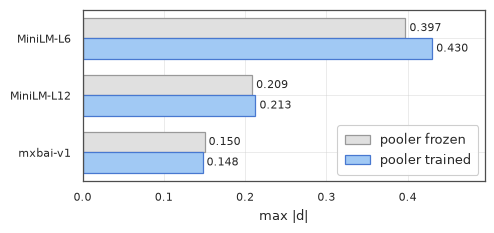

In [4]:
levels = paired_table(DATA_ROOT, "score_chosen", HELD_OUT)
y = np.arange(len(LABELS))
height = 0.36

fig, ax = plt.subplots(figsize=(0.8 * TEXT_WIDTH, 2.4))
for offset, column, fill, edge, label in (
    (-height / 2, "base_mean", MUTED_FILL, MUTED_EDGE, "pooler frozen"),
    (height / 2, "variant_mean", BAR_FILL, BAR_EDGE, "pooler trained"),
):
    ax.barh(
        y + offset,
        levels[column],
        height=height,
        color=fill,
        edgecolor=edge,
        linewidth=0.9,
        zorder=2,
        label=label,
    )
    for pos, value in zip(y + offset, levels[column], strict=True):
        ax.text(value + 0.005, pos, f"{value:.3f}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(LABELS)
ax.set_ylim(len(LABELS) - 0.5, -0.5)
ax.set_xlim(0, 1.15 * levels[["base_mean", "variant_mean"]].to_numpy().max())
ax.set_xlabel("max |d|")
ax.legend(
    loc="lower right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor="0.8",
    framealpha=0.95,
    borderpad=0.6,
).set_zorder(5)
save(fig, "pooler_transfer")

In [5]:
paired_table(DATA_ROOT, "score_delta", IN_TRAINING).round(3)

,base_mean,base_sd,variant_mean,variant_sd,variant_lower,untied,sign_p
MiniLM-L6,-0.192,0.050,-0.167,0.050,1,5,0.375
MiniLM-L12,-0.067,0.022,-0.047,0.022,1,5,0.375
mxbai-v1,-0.085,0.021,-0.122,0.034,4,5,0.375


At the chosen weight, held-out max |d| is 0.430 with the pooler trained against
0.397 with it frozen on MiniLM-L6, higher on all five seeds, 0.213 against 0.209
on MiniLM-L12 and 0.148 against 0.150 on mxbai-v1. Training the pooler leaves no
model less sensitive to the held-out format.

In [6]:
paired_table(DATA_ROOT, "answer_pct", HELD_OUT).round(3)

,base_mean,base_sd,variant_mean,variant_sd,variant_lower,untied,sign_p
MiniLM-L6,-41.082,19.079,-23.961,22.488,0,5,0.062
MiniLM-L12,-35.856,11.413,-38.793,13.978,4,5,0.375
mxbai-v1,-20.000,28.284,-30.000,28.284,2,2,0.500


Held-out conditional inconsistency is at most 1.3% under any control, a handful
of queries per fold, so the answer axis cannot separate the two heads.


## Head weight change


In [7]:
change = head_weight_change(DATA_ROOT, VARIANTS + list(XLMR))
change.round(3)

/home/dan/code/bath/format-sensitivity-reranking/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


role  control  chosen
model             module                                      
MiniLM-L6-pooler  bert.pooler.dense     dense    0.483   0.547
                  classifier           output    0.072   0.347
MiniLM-L12-pooler bert.pooler.dense     dense    0.333   0.395
                  classifier           output    0.039   0.163
mxbai-v1-pooler   classifier           output    0.111   0.103
                  pooler.dense          dense    0.124   0.112
bge-base          classifier.dense      dense    0.100   0.131
                  classifier.out_proj  output    0.122   0.350
bge-v2-m3         classifier.dense      dense    0.109   0.104
                  classifier.out_proj  output    0.117   0.250
jina-v2           classifier.dense      dense    0.133   0.139
                  classifier.out_proj  output    1.088   0.585

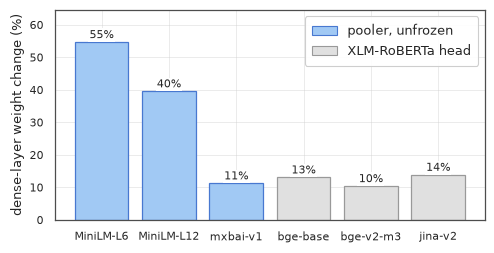

In [8]:
dense = change[change["role"] == DENSE].droplevel("module")[CHOSEN]
names = LABELS + [by_slug(slug).label for slug in XLMR]
trained = [True] * len(VARIANTS) + [False] * len(XLMR)
x = np.arange(len(names))

fig, ax = plt.subplots(figsize=(0.8 * TEXT_WIDTH, 2.6))
ax.bar(
    x,
    100 * dense.to_numpy(),
    zorder=2,
    color=[BAR_FILL if t else MUTED_FILL for t in trained],
    edgecolor=[BAR_EDGE if t else MUTED_EDGE for t in trained],
    linewidth=0.9,
)
for pos, value in zip(x, dense, strict=True):
    ax.text(
        pos,
        100 * value + 1.2,
        f"{100 * value:.0f}%",
        ha="center",
        fontsize=8,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("dense-layer weight change (%)")
ax.set_ylim(0, 100 * dense.max() * 1.18)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, fc=BAR_FILL, ec=BAR_EDGE, label="pooler, unfrozen"),
        plt.Rectangle(
            (0, 0), 1, 1, fc=MUTED_FILL, ec=MUTED_EDGE, label="XLM-RoBERTa head"
        ),
    ],
    loc="upper right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor="0.8",
    framealpha=0.95,
    borderpad=0.6,
)
save(fig, "pooler_weight_change")

The unfrozen pooler moves 11% on mxbai-v1, as far as the dense layer of the
three XLM-RoBERTa heads, and 40 to 55% on the MiniLM models, so it was
trained. Most of that movement is already present at $\lambda = 0$, from the
ranking loss rather than the invariance term.


## Ranking quality


In [9]:
paired_table(DATA_ROOT, "mrr_chosen", HELD_OUT).round(4)

,base_mean,base_sd,variant_mean,variant_sd,variant_lower,untied,sign_p
MiniLM-L6,0.9416,0.0014,0.9404,0.0016,5,5,0.0625
MiniLM-L12,0.9593,0.0010,0.9595,0.0009,1,5,0.3750
mxbai-v1,0.9677,0.0006,0.9687,0.0009,0,5,0.0625


Mean MRR at the chosen weight differs by at most 0.0012 between the two heads.
